# This script describes how to run ACCESS-OM2 1-degree simulations with perturbed forcing.

The perturbed forcing system is implemented in YATM, and described at https://github.com/COSIMA/access-om2/wiki/Tutorials#Scaling-the-forcing-fields.

Also note that there are several issues linked at the bottom of that post that may also be useful:
- https://github.com/COSIMA/libaccessom2/issues/30
- https://github.com/COSIMA/libaccessom2/issues/31

Note that the two configurations that I've used below to create these forcing perturbations are located on github at:
- https://github.com/rmholmes/1deg_jra55_iaf/tree/forcing_perturb_tutorial_control
- https://github.com/rmholmes/1deg_jra55_iaf/tree/forcing_perturb_tutorial_perturbation

## THIS VERSION IS FOR ERA5 SEPARABLE PERTURBATIONS

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob

from dask.distributed import Client

In [2]:
# Load workers:
client = Client(n_workers=4)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 4
Total threads: 4,Total memory: 18.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43075,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39675,Total threads: 1
Dashboard: /proxy/44391/status,Memory: 4.50 GiB
Nanny: tcp://127.0.0.1:34943,


In [46]:
# define input and output files:
year = 1980
source_file = '/g/data/rt52/era5/single-levels/reanalysis/2t/1980/2t_era5_oper_sfc_19800101-19800131.nc'.format(year=year)
out_file_sp = '/g/data/e14/rmh561/access-om2/perturbations/2t_era5_space.nc'
out_file_tm = '/g/data/e14/rmh561/access-om2/perturbations/2t_era5_time.nc'

In [47]:
# Load source file:
ds_source = xr.open_dataset(source_file)
ds_source

<xarray.Dataset> Size: 6GB
Dimensions:    (time: 744, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 6kB 1980-01-01 ... 1980-01-31T23:00:00
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    t2m        (time, latitude, longitude) float64 6GB ...
Attributes:
    Conventions:  CF-1.6
    history:      2020-10-04 15:35:20 UTC+1100 by era5_replication_tools-1.2....
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 single-levels reanalysis 2m_temperature 19800101-19800131

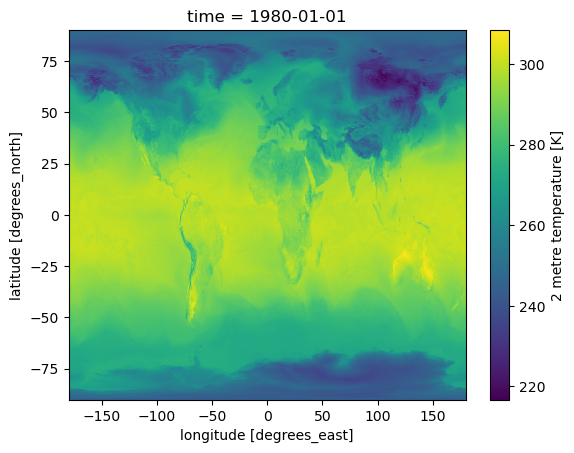

In [48]:
ds_source.t2m.isel(time=0).plot()

Now let's create our forcing perturbation. Here we will do a multiplicative perturbation where we simply multiply the zonal winds in the tropical Pacific region by a time-independent factor of 1.25.

<xarray.Dataset> Size: 8MB
Dimensions:    (latitude: 721, longitude: 1440)
Coordinates:
  * latitude   (latitude) float32 3kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    t2m        (latitude, longitude) float64 8MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
Attributes:
    Conventions:  CF-1.6
    history:      2020-10-04 15:35:20 UTC+1100 by era5_replication_tools-1.2....
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 single-levels reanalysis 2m_temperature 19800101-19800131

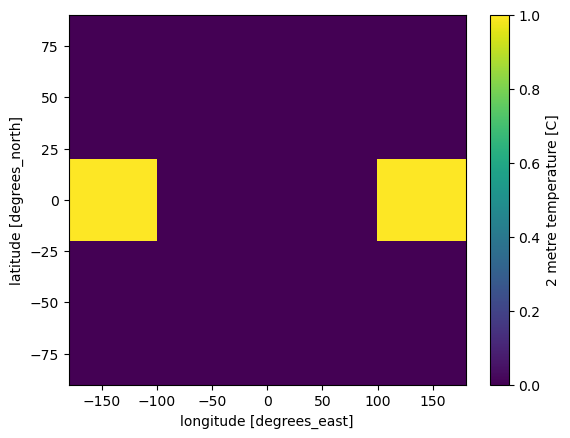

In [52]:
# Spatial perturbation:
ds_source_sp = ds_source.isel(time=0,drop=True).load()

# Define 2D lon/lat:
lat2d,lon2d = xr.broadcast(ds_source_sp.latitude,ds_source_sp.longitude)

# Define the tropical Pacific region:
region = np.logical_and(np.logical_or(lon2d <= -100.,lon2d >= 100.),np.logical_and(lat2d >= -20.,lat2d <= 20.))

# Set the offset factor:
ds_source_sp['t2m'].data = xr.where(region,1.,0.)

# Change the units:
ds_source_sp["t2m"].attrs["units"] = "C"
ds_source_sp["t2m"].encoding.pop("scale_factor", None)
ds_source_sp["t2m"].encoding.pop("add_offset", None)
ds_source_sp["t2m"].encoding.pop("_FillValue", None)

encoding = {}
for var in ds_source_sp.data_vars:
    encoding[var] = {
        "contiguous": True,
        "dtype": "float32"
    }

# Write-out to file:
ds_source_sp.to_netcdf(out_file_sp,encoding = encoding)

# Plot:
ds_source_sp.t2m.plot()

ds_source_sp

<xarray.Dataset> Size: 12kB
Dimensions:  (time: 744)
Coordinates:
  * time     (time) datetime64[ns] 6kB 1980-01-01 ... 1980-01-31T23:00:00
Data variables:
    t2m      (time) float64 6kB 0.0 0.001346 0.002692 ... 0.9973 0.9987 1.0
Attributes:
    Conventions:  CF-1.6
    history:      2020-10-04 15:35:20 UTC+1100 by era5_replication_tools-1.2....
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 single-levels reanalysis 2m_temperature 19800101-19800131

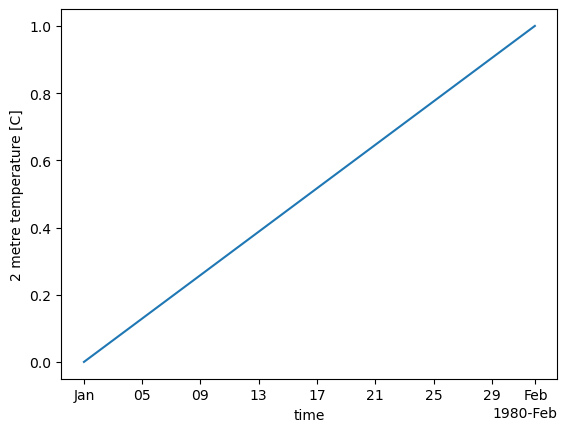

In [53]:
# temporal perturbation:
ds_source_tm = ds_source.isel(latitude=0,longitude=0,drop=True).load()

# Set the offset factor:
ds_source_tm['t2m'].data = np.linspace(0.,1.,len(ds_source_tm.time))

# Change the units:
ds_source_tm["t2m"].attrs["units"] = "C"
ds_source_tm["t2m"].encoding.pop("scale_factor", None)
ds_source_tm["t2m"].encoding.pop("add_offset", None)
ds_source_tm["t2m"].encoding.pop("_FillValue", None)

encoding = {}
for var in ds_source_tm.data_vars:
    encoding[var] = {
        "contiguous": True,
        "dtype": "float32"
    }

# Write-out to file:
ds_source_tm.to_netcdf(out_file_tm,encoding = encoding)

# Plot:
ds_source_tm.t2m.plot()

ds_source_tm

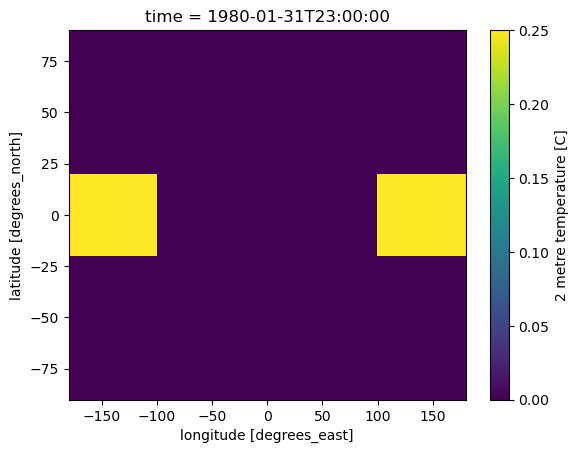

In [45]:
(ds_source_tm.t2m.isel(time=slice(0,5))*ds_source_sp.t2m)
(ds_source_tm.t2m.isel(time=-1)*ds_source_sp.t2m).plot()

## Finally, analyse the results

In [66]:
perturb_base = '/scratch/e14/rmh561/access-om2/archive/1deg_era5_iaf_ptest-era5_ptest-c39a236a/'
control_base = '/scratch/e14/rmh561/access-om2/archive/1deg_era5_iaf_ptest_control-era5_ptest_control-957a62a8/'

In [67]:
# Plot global surface temperature:
ds_control = xr.open_dataset(control_base + 'output000/ocean/ocean-2d-surface_pot_temp-1-daily-mean-ym_1980_01.nc')
ds_perturb = xr.open_dataset(perturb_base + 'output000/ocean/ocean-2d-surface_pot_temp-1-daily-mean-ym_1980_01.nc')

/jobfs/168775470.gadi-pbs/ipykernel_2683947/3176050245.py:2: FutureWarning: In a future version, xarray will not decode the variable 'average_DT' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds_control = xr.open_dataset(control_base + 'output000/ocean/ocean-2d-surface_pot_temp-1-daily-mean-ym_1980_01.nc')
/jobfs/168775470.gadi-pbs/ipykernel_2683947/3176050245.py:2: FutureWarning: In a future version, xarray will not decode the variable 'time_bnds' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will 

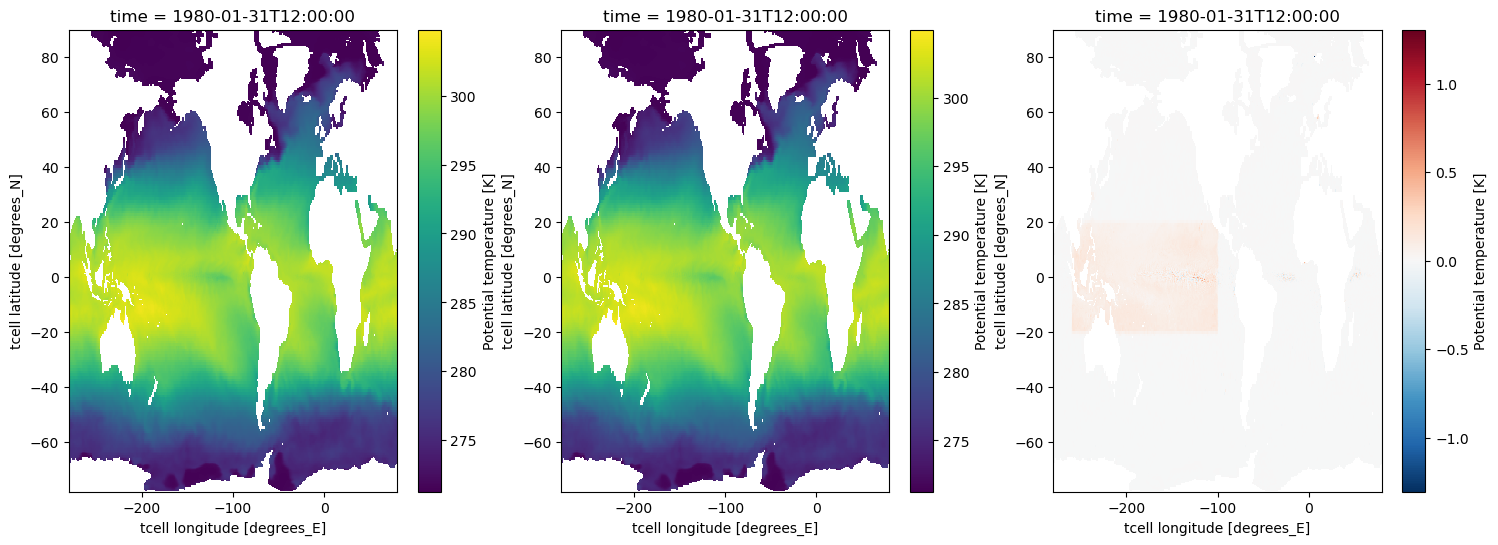

In [68]:
fig, axes = plt.subplots(nrows=1,ncols=3,figsize=(18,6))
ds_control.surface_pot_temp.isel(time=-1).plot(ax=axes[0])
ds_perturb.surface_pot_temp.isel(time=-1).plot(ax=axes[1])
(ds_perturb.surface_pot_temp.isel(time=-1)-ds_control.surface_pot_temp.isel(time=-1)).plot(ax=axes[2])